# 01 · Market volume

How many IT jobs were posted from 2020 to 2026, and can the count tell us whether the market grew?

**Method.** One row per *unique* IT posting: Jev labelled the title `tech` (confidence ≥ 0.6) and the
fingerprint step did not mark it a repeat (`fp_dup = false`). Months stop at **2026-10**, the last full
month. Every count is paired with the IT share of the *same source's* postings, because the feed's
sources change by era (see AGENT.MD) and a raw count mostly follows the scraper, not the market.

Data stays in `data/`; this notebook saves only aggregate tables (`tables/`) and charts (`charts/`).

In [1]:
from vnjobs.analysis import core as a
from vnjobs.analysis import volume as v

a.apply_style()
con = a.connect()

## 1. The total is a map of the scrapers

Stacking IT postings by source shows each source switching on and off. A rise in the stack is mostly a new source arriving.

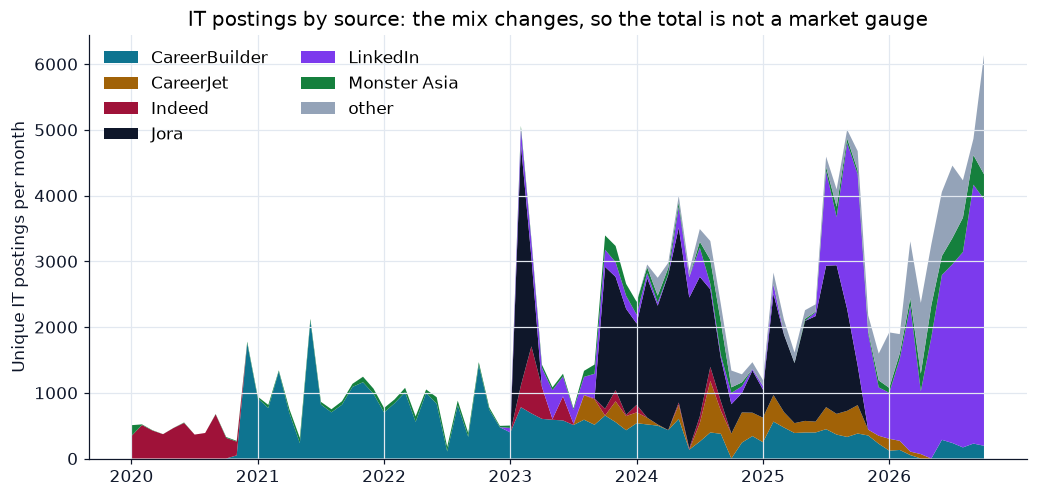

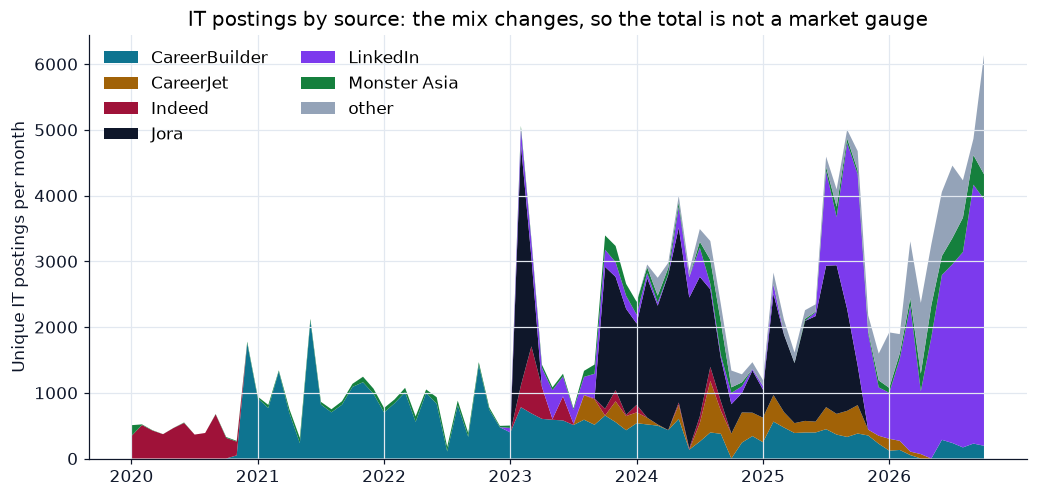

In [2]:
monthly = v.monthly_by_source(con)
fig = v.chart_stacked_sources(monthly)
a.save_chart(fig, "01-it-postings-by-source")
a.save_table(monthly.assign(source=monthly.source.map(a.source_label)), "01-it-postings-by-source")
fig

## 2. Within one source, the IT share is the comparable number

Across sources the IT share differs several times over (CareerBuilder and Jora ≈ 6 %, LinkedIn ≈ 17–34 %), so switching source changes the headline share without the market moving. Even one source moves by several points from year to year, so read these lines as a rough band, not a precise trend.

source,careerbuilder_vn,careerjet_vn,jora_vn,linkedin_vn,monsterasia_vn
year,,,,,
2020,9.1,NaN,NaN,NaN,21.2
2021,9.3,NaN,NaN,NaN,11.2
2022,7.9,NaN,NaN,11.8,13.3
2023,6.3,17.0,6.0,22.1,13.5
2024,6.0,16.1,5.5,17.3,16.5
2025,5.7,17.4,6.0,33.5,12.2
2026,6.7,21.0,NaN,25.7,18.1


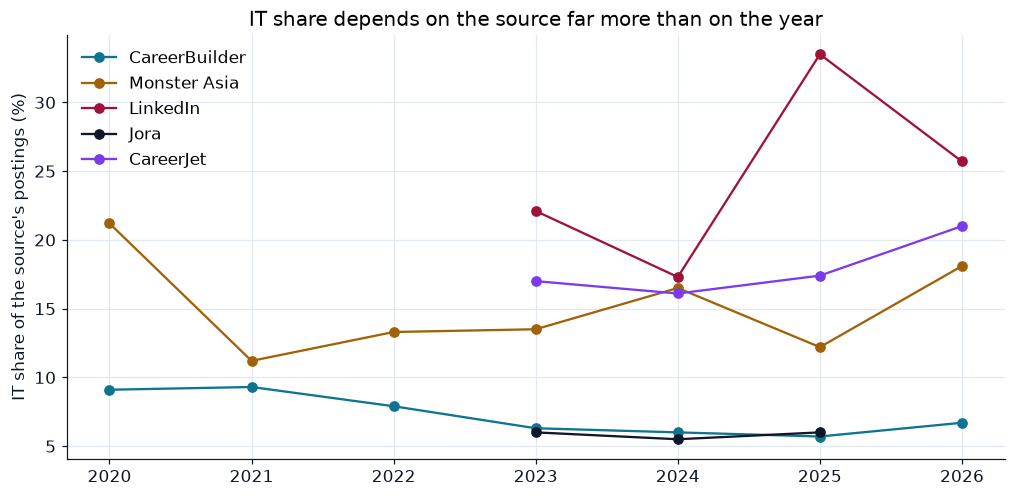

In [3]:
shares = v.share_by_source_year(con)
fig = v.chart_share_by_source(shares)
a.save_chart(fig, "01-it-share-by-source")
a.save_table(shares.assign(source=shares.source.map(a.source_label)), "01-it-share-by-source-year")
shares[shares.source.isin(v.SHARE_SOURCES)].pivot(index="year", columns="source", values="it_share")

## 3. CareerBuilder, the biggest source that spans the years

CareerBuilder runs from November 2020 to 2026, so it is the cleanest large single-source trend. (Monster Asia spans every month but is an order of magnitude smaller.) CareerBuilder's postings fell as a whole, so we read its IT *share*, not the count.

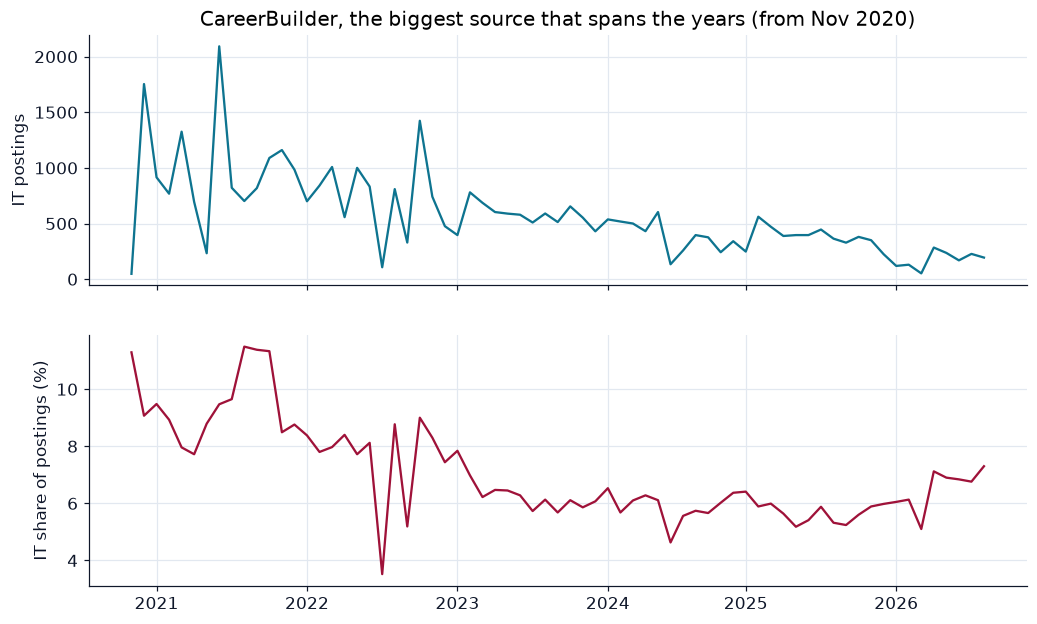

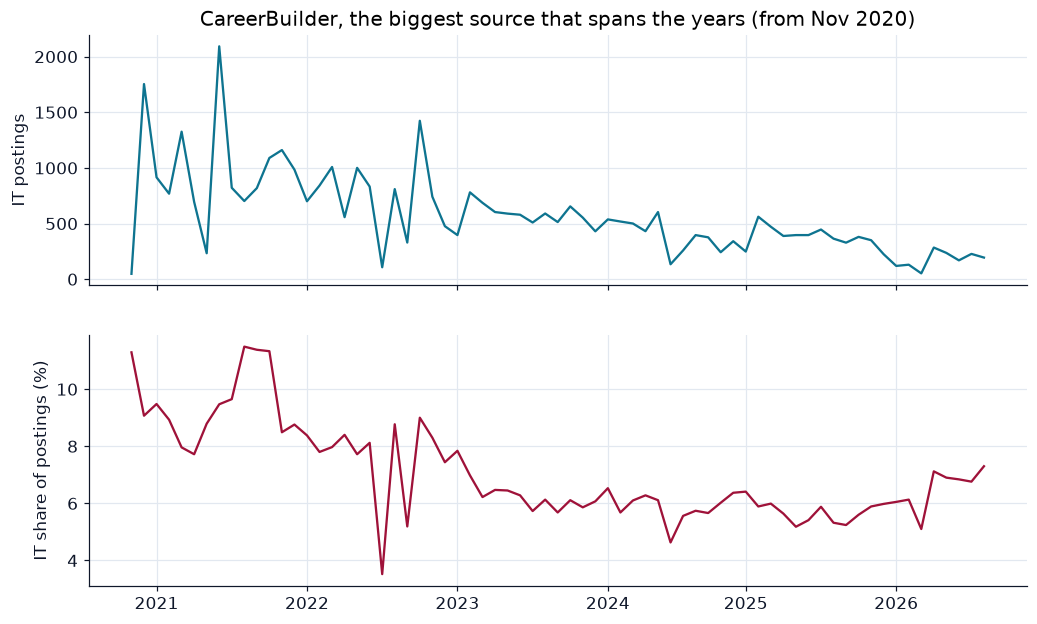

In [4]:
careerbuilder = v.monthly_source_share(con, "careerbuilder_vn")
fig = v.chart_careerbuilder(careerbuilder)
a.save_chart(fig, "01-careerbuilder-monthly")
a.save_table(careerbuilder, "01-careerbuilder-monthly")
fig

## 4. Years to 2022, quarters from 2023

Early years are too thin to split. The all-source IT share jumps to 14–17 % from 2025-Q4. That is the mix: Jora (about 6 % IT) stops after October 2025 while LinkedIn (25–33 %) grows. IT did not double.

In [5]:
periods = v.period_table(con)
a.save_table(periods, "01-it-postings-by-period")
periods

,period,it_postings,all_postings,it_share
0,2020,6643,148184.0,4.5
1,2021,12214,130402.0,9.4
2,2022,9547,116830.0,8.2
3,2023-Q1,8899,118393.0,7.5
4,2023-Q2,3798,41648.0,9.1
5,2023-Q3,3524,37186.0,9.5
6,2023-Q4,9282,141138.0,6.6
7,2024-Q1,8083,124075.0,6.5
8,2024-Q2,9830,158742.0,6.2
9,2024-Q3,9144,109433.0,8.4


## 5. 2026 so far against the same months of 2025

January to October of each year. Sources that exist in only one window (Jora in 2025, CareerViet in 2026) are why the windows are not like for like, so there is no total row: compare a source with itself.

In [6]:
ytd = v.ytd_table(con)
a.save_table(ytd, "01-ytd-2026-vs-2025")
ytd

,source,it_2025,it_2026,all_2025,all_2026,share_2025,share_2026
0,LinkedIn,7872,22845,23331.0,88866.0,33.7,25.7
1,CareerViet,0,5190,NaN,92395.0,NaN,5.6
2,Monster Asia,408,3072,2995.0,16989.0,13.6,18.1
3,CareerBuilder,3978,1411,70564.0,21000.0,5.6,6.7
4,SmartRecruiters,556,862,1667.0,2187.0,33.4,39.4
5,DEjobs,56,509,1009.0,6633.0,5.6,7.7
6,Foundit,0,482,NaN,2260.0,NaN,21.3
7,CareerJet,2982,440,17326.0,2097.0,17.2,21.0
8,Lever,115,205,335.0,604.0,34.3,33.9
9,Manatal,226,192,1519.0,2492.0,14.9,7.7


## 6. When in the year

CareerBuilder is the one large source with full calendar years from 2021 to 2025, so the seasonal pattern is read inside it. Each month's count is divided by that year's average month: 1.0 is a normal month.

,month,all_index,it_index,it_min,it_max
0,1,0.74,0.81,0.65,0.95
1,2,1.16,1.19,0.79,1.48
2,3,1.34,1.29,1.20,1.37
3,4,0.91,0.89,0.72,1.05
4,5,0.95,0.92,0.24,1.36
5,6,1.33,1.34,1.01,2.16
6,7,0.81,0.76,0.15,1.18
7,8,0.91,0.95,0.73,1.10
8,9,0.82,0.76,0.45,0.89
9,10,1.20,1.30,1.00,1.94


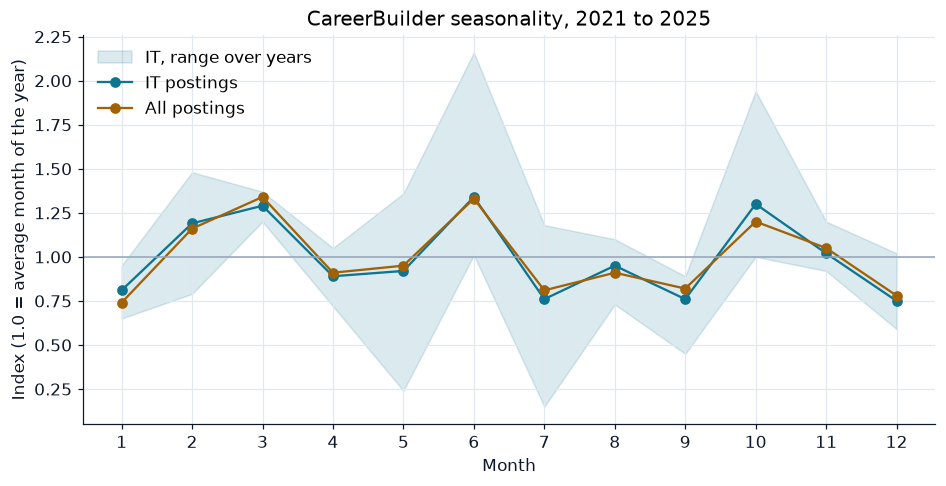

In [7]:
season = v.seasonality(con)
fig = v.chart_seasonality(season)
a.save_chart(fig, "01-seasonality")
a.save_table(season, "01-seasonality")
season

## Findings

1. **The IT count is not a market gauge.** Monthly unique IT postings run roughly 500–2,000 in 2021–22 and mostly 1,000–5,000 from 2023 (6,000 by late 2026), but each step up lines up with a source switching on: Jora in February 2023, LinkedIn through 2025 and 2026. Jora, the biggest 2023–25 source, stops after October 2025.
2. **On CareerBuilder, IT's share of postings fell, then flattened.** 9.3 % in 2021, 7.9 % in 2022, 6.3 % in 2023, 6.0 % in 2024, 5.7 % in 2025, then 6.7 % for January–October 2026. That is the best single-source read we have, and it says IT's slice of that board got smaller from 2021 to 2023 and has been roughly flat since.
3. **Other sources are higher and noisier.** LinkedIn runs 17–34 %, CareerJet 16–21 %, Monster Asia 11–21 %, so the all-source share of 14–17 % since 2025-Q4 is mostly the source mix.
4. **Caveats.** CareerBuilder's own postings dropped from 125k (2021) to 80k (2025) and 21k in ten months of 2026, which looks like scraper coverage, not only the market. IT is decided from the title alone (Jev, ≥ 0.6), so borderline titles move the share a little.
5. **A seasonal pattern inside CareerBuilder (2021–2025).** IT postings run above an average month in March (index 1.29), June (1.34) and October (1.30), and in February (1.19), and below it in January (0.81), July (0.76), September (0.76) and December (0.75). The ranges across years are wide (June 1.01 to 2.16, July 0.15 to 1.18), which could be real swings or collection gaps, so treat the pattern as indicative.

**What this notebook cannot say:** whether the number of IT jobs grew. It can say how IT's share of postings moved on the one large source that lasts across the years.